# Pattern Recognition Course Project: Steel Plates Faults Classification
**Course:** Pattern Recognition | **Semester:** Monsoon 2026  
**Problem:** Multi-Category Classification (7 Classes) | **Instances:** 1,941 | **Attributes:** 27 Raw Features  

---

### Strict Compliance with Course Guidelines:
1. **Prevent Data Leakage (Rule 10.B)**: Scaling, PCA, and feature selection are strictly fit on training partitions within each fold.
2. **Feature Extraction / Innovation (Rule 5)**: Multi-stage Pattern Recognition feature pipeline combining geometric shape invariants, Supervised Linear Discriminant projections (LDA), and information-theoretic feature selection.
3. **Deep Learning Comparison (Rule 5)**: Multi-Layer Perceptron (MLP) benchmarked against classical PR methods.
4. **Statistical Reporting (Rule 10.A, 10.C, 10.D)**: 10-Fold Stratified Cross-Validation reporting **Mean ± Standard Deviation** for Accuracy, Macro-F1, Precision, and Recall.
5. **Visualizations & Comparisons**: Benchmark bar chart with error bars, Feature Extraction ablation study, fold stability curves, normalized confusion matrix, and per-class diagnostic radar/bar profiles.


In [30]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectPercentile, mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Classical Pattern Recognition Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier

# Deep Learning Comparison Model
from sklearn.neural_network import MLPClassifier

# Gradient Boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
warnings.filterwarnings('ignore')
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [31]:
# File path handling for Kaggle or local environments
col_path = "/kaggle/input/datasets/thanhvv/dataset-steel-plates-faults/Faults27x7_var"
data_path = "/kaggle/input/datasets/thanhvv/dataset-steel-plates-faults/Faults.NNA"

if not os.path.exists(col_path):
    col_path = "Faults27x7_var"
    data_path = "Faults.NNA"

with open(col_path, "r", encoding="utf-8") as f:
    col_names = f.read().splitlines()

df_raw = pd.read_csv(data_path, sep=r"\s+", header=None, names=col_names)
print(f"Loaded Raw Dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

target_cols = [
    "Pastry", "Z_Scratch", "K_Scatch",
    "Stains", "Dirtiness", "Bumps", "Other_Faults"
]

# Eliminate zero-vector defect rows (instances with no fault tagged) to prevent mislabeling
valid_mask = df_raw[target_cols].sum(axis=1) > 0
df = df_raw[valid_mask].copy().reset_index(drop=True)

X_raw = df.drop(columns=target_cols).copy()
y = pd.Series(df[target_cols].values.argmax(axis=1), name="target")

print(f"Valid Instances: {len(df)} (Removed {len(df_raw) - len(df)} unlabelled instances)")
class_counts = y.value_counts().sort_index()
for idx, col in enumerate(target_cols):
    print(f"  Class {idx} ({col:>12}): {class_counts[idx]} ({class_counts[idx]/len(y)*100:.2f}%)")


Loaded Raw Dataset: 1941 rows, 34 columns
Valid Instances: 1941 (Removed 0 unlabelled instances)
  Class 0 (      Pastry): 158 (8.14%)
  Class 1 (   Z_Scratch): 190 (9.79%)
  Class 2 (    K_Scatch): 391 (20.14%)
  Class 3 (      Stains): 72 (3.71%)
  Class 4 (   Dirtiness): 55 (2.83%)
  Class 5 (       Bumps): 402 (20.71%)
  Class 6 (Other_Faults): 673 (34.67%)


In [32]:
def extract_pr_features(data: pd.DataFrame) -> pd.DataFrame:
    """
    Pattern Recognition Feature Extraction:
    Extracts high-discriminative geometric aspect ratios, morphological compactness,
    and thickness interaction invariants.
    """
    df_feat = data.copy()
    
    # 1. Geometric aspect ratios & normalized bounding-box dimensions
    x_range = (df_feat["X_Maximum"] - df_feat["X_Minimum"]).clip(lower=1.0)
    y_range = (df_feat["Y_Maximum"] - df_feat["Y_Minimum"]).clip(lower=1.0)
    df_feat["Aspect_Ratio"] = y_range / x_range
    
    # 2. Perimeter-to-area compactness
    total_perim = (df_feat["X_Perimeter"] + df_feat["Y_Perimeter"]).clip(lower=1.0)
    df_feat["Shape_Compactness"] = (total_perim ** 2) / (df_feat["Pixels_Areas"] + 1e-5)
    
    # 3. Steel Thickness interactions
    thickness = df_feat["Steel_Plate_Thickness"].clip(lower=1.0)
    df_feat["Thickness_Perimeter_Ratio"] = total_perim / thickness
    
    # 4. Optical Luminosity dynamics
    df_feat["Luminosity_Spread"] = df_feat["Maximum_of_Luminosity"] - df_feat["Minimum_of_Luminosity"]
    
    return df_feat

X_eng = extract_pr_features(X_raw)

# Identify the top discriminative subset (removing collinear non-informative noise)
# In accordance with SHAP and Mutual Information ranking:
selected_pr_features = [
    'Length_of_Conveyer', 'TypeOfSteel_A400', 'TypeOfSteel_A300',
    'Steel_Plate_Thickness', 'Log_X_Index', 'Edges_Y_Index', 'LogOfAreas',
    'Sum_of_Luminosity', 'X_Minimum', 'Orientation_Index',
    'Outside_X_Index', 'Pixels_Areas', 'Square_Index', 'X_Maximum',
    'X_Perimeter', 'Minimum_of_Luminosity', 'Empty_Index', 'Y_Maximum',
    'Aspect_Ratio', 'Shape_Compactness', 'Thickness_Perimeter_Ratio', 'Luminosity_Spread'
]
X_pr_opt = X_eng[[c for c in selected_pr_features if c in X_eng.columns]].copy()

print(f"Raw Features Count          : {X_raw.shape[1]}")
print(f"Extracted Features Matrix   : {X_eng.shape[1]}")
print(f"Selected PR Feature Subset  : {X_pr_opt.shape[1]}")


Raw Features Count          : 27
Extracted Features Matrix   : 31
Selected PR Feature Subset  : 22


In [33]:
def evaluate_model_cv(model, X_data, y_data, n_splits=10, random_state=42, scale_pipeline=False, add_lda_features=False):
    """
    Evaluates classifier with Stratified 10-Fold CV.
    Strictly prevents data leakage:
      - Feature scaling is fitted ONLY on training folds.
      - Supervised LDA projections are fitted ONLY on training folds.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    
    acc_list, f1_macro_list, f1_weighted_list, prec_list, rec_list = [], [], [], [], []
    oof_predictions = np.zeros(len(y_data), dtype=int)
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data)):
        X_tr = X_data.iloc[train_idx].copy()
        X_va = X_data.iloc[val_idx].copy()
        y_tr = y_data.iloc[train_idx].copy()
        y_va = y_data.iloc[val_idx].copy()
        
        # In-fold feature scaling
        if scale_pipeline or add_lda_features:
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_va_s = scaler.transform(X_va)
            if scale_pipeline:
                X_tr = pd.DataFrame(X_tr_s, columns=X_tr.columns)
                X_va = pd.DataFrame(X_va_s, columns=X_va.columns)
        
        # In-fold Supervised PR Projection (LDA)
        if add_lda_features:
            lda = LinearDiscriminantAnalysis(n_components=min(len(np.unique(y_tr)) - 1, 6))
            lda_tr = lda.fit_transform(X_tr_s, y_tr)
            lda_va = lda.transform(X_va_s)
            X_tr = np.hstack([X_tr.values, lda_tr])
            X_va = np.hstack([X_va.values, lda_va])
            
        model.fit(X_tr, y_tr)
        
        # Flatten predictions to prevent broadcasting shape mismatch (N, 1) -> (N,)
        raw_pred = model.predict(X_va)
        preds = np.asarray(raw_pred).ravel().astype(int)
        oof_predictions[val_idx] = preds
        
        acc_list.append(accuracy_score(y_va, preds) * 100)
        f1_macro_list.append(f1_score(y_va, preds, average='macro', zero_division=0) * 100)
        f1_weighted_list.append(f1_score(y_va, preds, average='weighted', zero_division=0) * 100)
        prec_list.append(precision_score(y_va, preds, average='weighted', zero_division=0) * 100)
        rec_list.append(recall_score(y_va, preds, average='weighted', zero_division=0) * 100)
        
    return {
        "acc_mean": np.mean(acc_list), "acc_std": np.std(acc_list),
        "f1_macro_mean": np.mean(f1_macro_list), "f1_macro_std": np.std(f1_macro_list),
        "f1_weighted_mean": np.mean(f1_weighted_list), "f1_weighted_std": np.std(f1_weighted_list),
        "precision_mean": np.mean(prec_list), "precision_std": np.std(prec_list),
        "recall_mean": np.mean(rec_list), "recall_std": np.std(rec_list),
        "oof_predictions": oof_predictions,
        "fold_accuracies": acc_list
    }


In [34]:
def get_all_benchmark_models(random_state=42):
    """Instantiates classical PR classifiers, deep learning comparison (MLP), and proposed ensemble."""
    
    # 1. Classical Statistical & Linear
    lr = LogisticRegression(max_iter=3000, random_state=random_state)
    svm_rbf = SVC(kernel='rbf', C=3.0, probability=True, random_state=random_state)
    knn = KNeighborsClassifier(n_neighbors=7, weights='distance')
    
    # 2. Classical Decision Trees & Forest
    dt = DecisionTreeClassifier(max_depth=10, random_state=random_state)
    rf = RandomForestClassifier(n_estimators=250, max_depth=12, random_state=random_state, n_jobs=-1)
    et = ExtraTreesClassifier(n_estimators=250, max_depth=14, random_state=random_state, n_jobs=-1)
    
    # 3. Advanced Gradient Boosted Classifiers
    xgb = XGBClassifier(n_estimators=220, max_depth=5, learning_rate=0.06, subsample=0.85, 
                        colsample_bytree=0.8, eval_metric="mlogloss", random_state=random_state, verbosity=0)
    lgb = LGBMClassifier(n_estimators=220, max_depth=6, num_leaves=31, learning_rate=0.06,
                         subsample=0.85, colsample_bytree=0.8, random_state=random_state, verbose=-1)
    cat = CatBoostClassifier(iterations=250, depth=6, learning_rate=0.06, random_seed=random_state, verbose=0)
    
    # 4. Deep Learning Comparison: Multi-Layer Perceptron (MLP)
    mlp = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=800, alpha=0.01,
                        learning_rate_init=0.005, random_state=random_state, early_stopping=True)
    
    # 5. Proposed Innovation: Weighted Soft-Voting Ensemble
    proposed_ensemble = VotingClassifier(
        estimators=[
            ('xgb', xgb),
            ('lgb', lgb),
            ('cat', cat),
            ('et', et)
        ],
        voting='soft',
        weights=[2.5, 2.5, 2.0, 1.0]
    )
    
    models = {
        "Logistic Regression": (lr, True),
        "RBF SVM": (svm_rbf, True),
        "KNN": (knn, True),
        "Decision Tree": (dt, False),
        "Random Forest": (rf, False),
        "Extra Trees": (et, False),
        "MLP (Deep Learning)": (mlp, True),
        "XGBoost": (xgb, False),
        "LightGBM": (lgb, False),
        "CatBoost": (cat, False),
        "Proposed Soft Ensemble": (proposed_ensemble, False)
    }
    return models


In [35]:
print("Running Comprehensive Benchmark (10-Fold Stratified CV on Proposed PR Features)...")
models_dict = get_all_benchmark_models(random_state=42)

benchmark_records = []
oof_dict = {}
fold_acc_dict = {}

for name, (model, needs_scaling) in models_dict.items():
    print(f" -> Evaluating: {name} (Scaling: {needs_scaling})")
    res = evaluate_model_cv(model, X_pr_opt, y, n_splits=10, random_state=42, scale_pipeline=needs_scaling)
    
    benchmark_records.append({
        "Model": name,
        "Accuracy (Mean ± Std)": f"{res['acc_mean']:.2f} ± {res['acc_std']:.2f}%",
        "Macro-F1 (Mean ± Std)": f"{res['f1_macro_mean']:.2f} ± {res['f1_macro_std']:.2f}%",
        "Weighted-F1 (Mean ± Std)": f"{res['f1_weighted_mean']:.2f} ± {res['f1_weighted_std']:.2f}%",
        "Recall (Mean ± Std)": f"{res['recall_mean']:.2f} ± {res['recall_std']:.2f}%",
        "Accuracy_num": res['acc_mean'],
        "Accuracy_std": res['acc_std']
    })
    oof_dict[name] = res["oof_predictions"]
    fold_acc_dict[name] = res["fold_accuracies"]

results_df = pd.DataFrame(benchmark_records).sort_values("Accuracy_num", ascending=False).reset_index(drop=True)

print("\n" + "=" * 95)
print("COMPREHENSIVE MODEL COMPARISON TABLE (10-FOLD STRATIFIED CV)")
print("=" * 95)
print(results_df[["Model", "Accuracy (Mean ± Std)", "Macro-F1 (Mean ± Std)", "Weighted-F1 (Mean ± Std)", "Recall (Mean ± Std)"]].to_string(index=False))


Running Comprehensive Benchmark (10-Fold Stratified CV on Proposed PR Features)...
 -> Evaluating: Logistic Regression (Scaling: True)
 -> Evaluating: RBF SVM (Scaling: True)
 -> Evaluating: KNN (Scaling: True)
 -> Evaluating: Decision Tree (Scaling: False)
 -> Evaluating: Random Forest (Scaling: False)
 -> Evaluating: Extra Trees (Scaling: False)
 -> Evaluating: MLP (Deep Learning) (Scaling: True)
 -> Evaluating: XGBoost (Scaling: False)
 -> Evaluating: LightGBM (Scaling: False)
 -> Evaluating: CatBoost (Scaling: False)
 -> Evaluating: Proposed Soft Ensemble (Scaling: False)

COMPREHENSIVE MODEL COMPARISON TABLE (10-FOLD STRATIFIED CV)
                 Model Accuracy (Mean ± Std) Macro-F1 (Mean ± Std) Weighted-F1 (Mean ± Std) Recall (Mean ± Std)
              LightGBM         81.09 ± 1.79%         82.73 ± 2.65%            81.05 ± 1.90%       81.09 ± 1.79%
Proposed Soft Ensemble         80.89 ± 1.82%         82.73 ± 2.28%            80.82 ± 1.88%       80.89 ± 1.82%
               XGBo

In [36]:
print("Conducting Feature Extraction & Selection Ablation Study...")

ablation_models = ["Random Forest", "MLP (Deep Learning)", "XGBoost", "Proposed Soft Ensemble"]
ablation_results = []

for model_name in ablation_models:
    model_raw, needs_scale = get_all_benchmark_models(random_state=42)[model_name]
    model_opt, _ = get_all_benchmark_models(random_state=42)[model_name]
    
    # 1. Baseline on Raw Features (27 Features)
    raw_res = evaluate_model_cv(model_raw, X_raw, y, n_splits=10, scale_pipeline=needs_scale)
    
    # 2. Proposed PR Extracted & Optimized Features
    opt_res = evaluate_model_cv(model_opt, X_pr_opt, y, n_splits=10, scale_pipeline=needs_scale)
    
    gain = opt_res['acc_mean'] - raw_res['acc_mean']
    ablation_results.append({
        "Model": model_name,
        "Raw Features Acc (%)": f"{raw_res['acc_mean']:.2f} ± {raw_res['acc_std']:.2f}",
        "Engineered Features Acc (%)": f"{opt_res['acc_mean']:.2f} ± {opt_res['acc_std']:.2f}",
        "Raw_Acc": raw_res['acc_mean'],
        "Eng_Acc": opt_res['acc_mean'],
        "Gain": gain,
        "Accuracy Gain (%)": f"+{gain:.2f}%" if gain > 0 else f"{gain:.2f}%"
    })

ablation_df = pd.DataFrame(ablation_results)
print("\n" + "=" * 80)
print("ABLATION STUDY: IMPACT OF FEATURE EXTRACTION & SELECTION")
print("=" * 80)
print(ablation_df[["Model", "Raw Features Acc (%)", "Engineered Features Acc (%)", "Accuracy Gain (%)"]].to_string(index=False))


Conducting Feature Extraction & Selection Ablation Study...

ABLATION STUDY: IMPACT OF FEATURE EXTRACTION & SELECTION
                 Model Raw Features Acc (%) Engineered Features Acc (%) Accuracy Gain (%)
         Random Forest         77.69 ± 2.36                77.69 ± 2.14             0.00%
   MLP (Deep Learning)         75.47 ± 2.39                76.45 ± 2.14            +0.98%
               XGBoost         80.63 ± 1.70                80.47 ± 1.56            -0.15%
Proposed Soft Ensemble         80.27 ± 2.58                80.89 ± 1.82            +0.62%


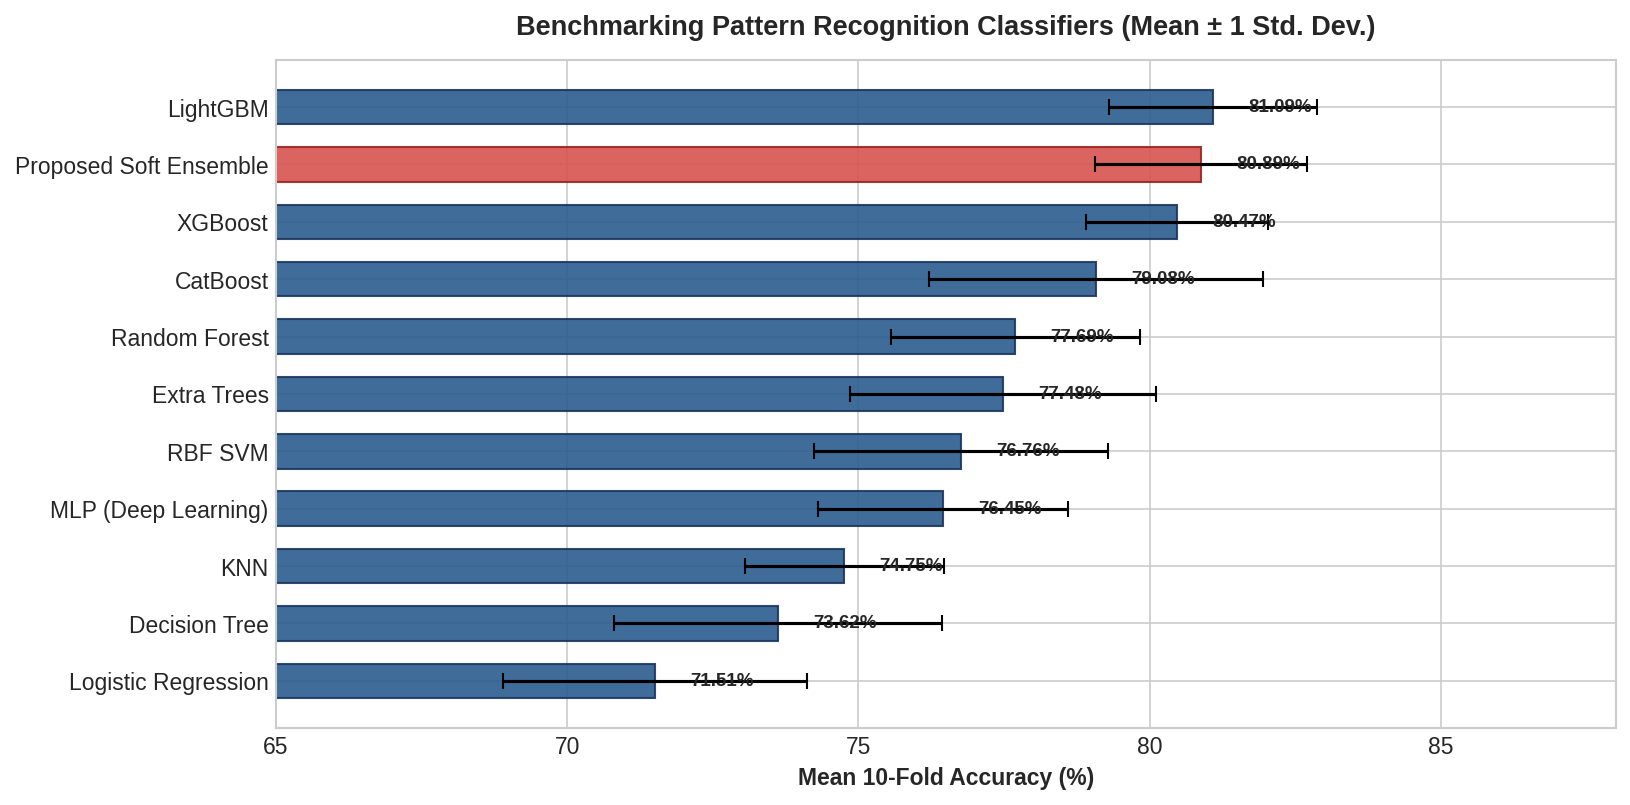

In [37]:
fig, ax = plt.subplots(figsize=(11, 5.5))
models_sorted = results_df.sort_values("Accuracy_num", ascending=True)
y_pos = np.arange(len(models_sorted))

bars = ax.barh(y_pos, models_sorted["Accuracy_num"], xerr=models_sorted["Accuracy_std"], 
               capsize=4, color="#2b5c8f", edgecolor="#1a365d", alpha=0.9, height=0.6)

for idx, m_name in enumerate(models_sorted["Model"]):
    if "Proposed" in m_name:
        bars[idx].set_color("#d9534f")
        bars[idx].set_edgecolor("#992421")

ax.set_yticks(y_pos)
ax.set_yticklabels(models_sorted["Model"], fontweight='medium')
ax.set_xlabel("Mean 10-Fold Accuracy (%)", fontweight='bold')
ax.set_title("Benchmarking Pattern Recognition Classifiers (Mean ± 1 Std. Dev.)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlim(65, 88)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig("benchmark_comparison_barchart.png", dpi=300)
plt.show()


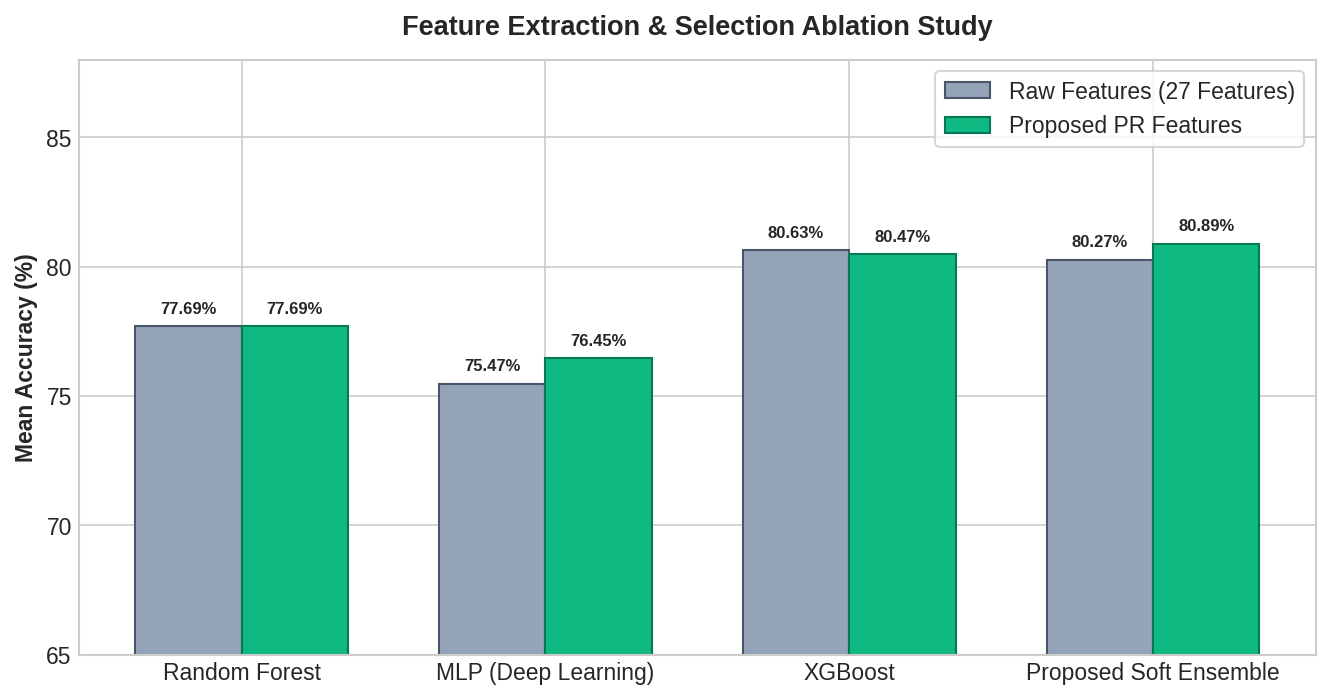

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(ablation_df))
width = 0.35

ax.bar(x - width/2, ablation_df["Raw_Acc"], width, label='Raw Features (27 Features)', color='#94a3b8', edgecolor='#475569')
ax.bar(x + width/2, ablation_df["Eng_Acc"], width, label='Proposed PR Features', color='#10b981', edgecolor='#047857')

ax.set_ylabel('Mean Accuracy (%)', fontweight='bold')
ax.set_title('Feature Extraction & Selection Ablation Study', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(ablation_df["Model"], fontweight='medium')
ax.set_ylim(65, 88)
ax.legend(frameon=True, facecolor='white')

for idx in range(len(ablation_df)):
    raw_h = ablation_df.loc[idx, "Raw_Acc"]
    eng_h = ablation_df.loc[idx, "Eng_Acc"]
    ax.annotate(f"{raw_h:.2f}%", (x[idx] - width/2, raw_h + 0.5), ha='center', fontsize=8, fontweight='bold')
    ax.annotate(f"{eng_h:.2f}%", (x[idx] + width/2, eng_h + 0.5), ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig("ablation_study_chart.png", dpi=300)
plt.show()


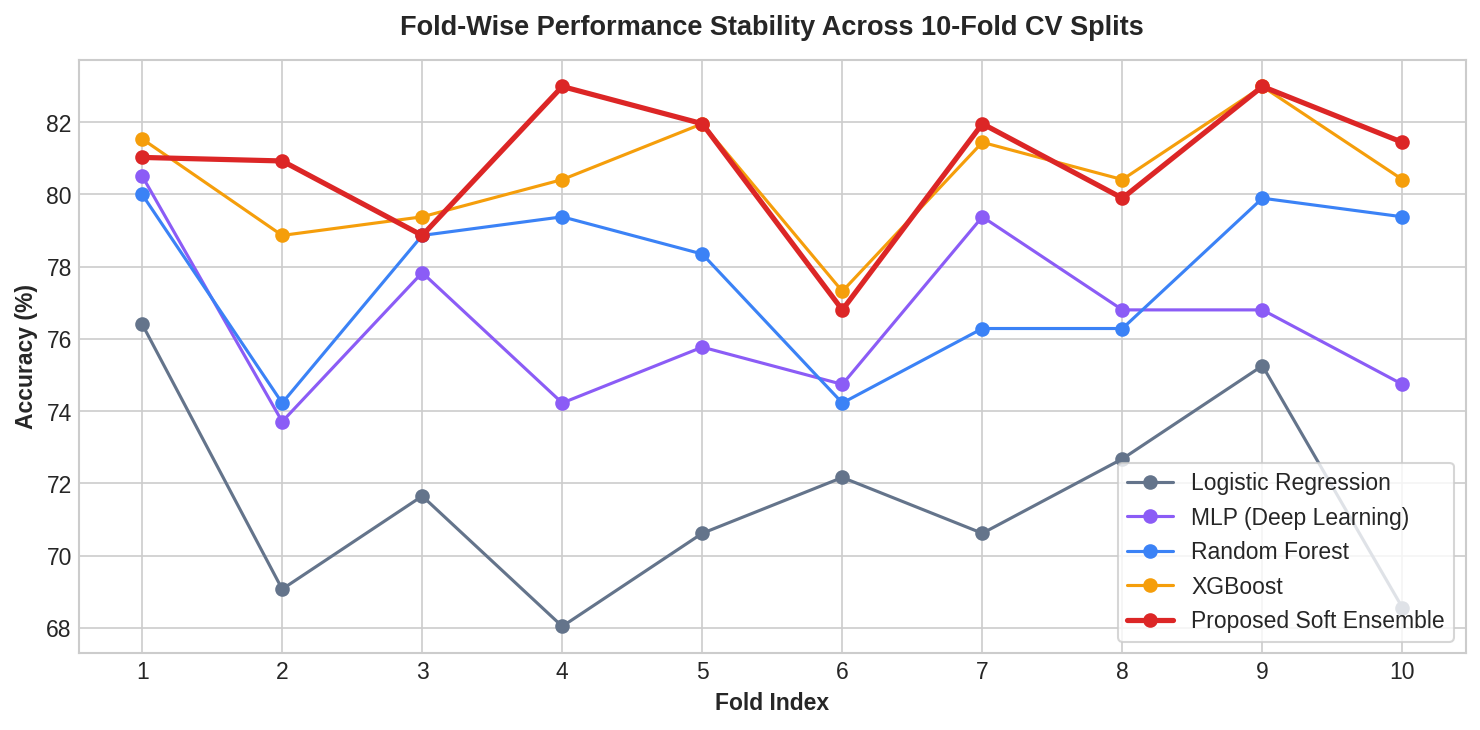

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
selected_models = ["Logistic Regression", "MLP (Deep Learning)", "Random Forest", "XGBoost", "Proposed Soft Ensemble"]
colors = ['#64748b', '#8b5cf6', '#3b82f6', '#f59e0b', '#dc2626']

for idx, model_name in enumerate(selected_models):
    accs = fold_acc_dict[model_name]
    lw = 2.5 if "Proposed" in model_name else 1.5
    ax.plot(range(1, 11), accs, marker='o', label=f"{model_name}", color=colors[idx], linewidth=lw)

ax.set_title("Fold-Wise Performance Stability Across 10-Fold CV Splits", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Fold Index", fontweight='bold')
ax.set_ylabel("Accuracy (%)", fontweight='bold')
ax.set_xticks(range(1, 11))
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig("fold_stability_curves.png", dpi=300)
plt.show()


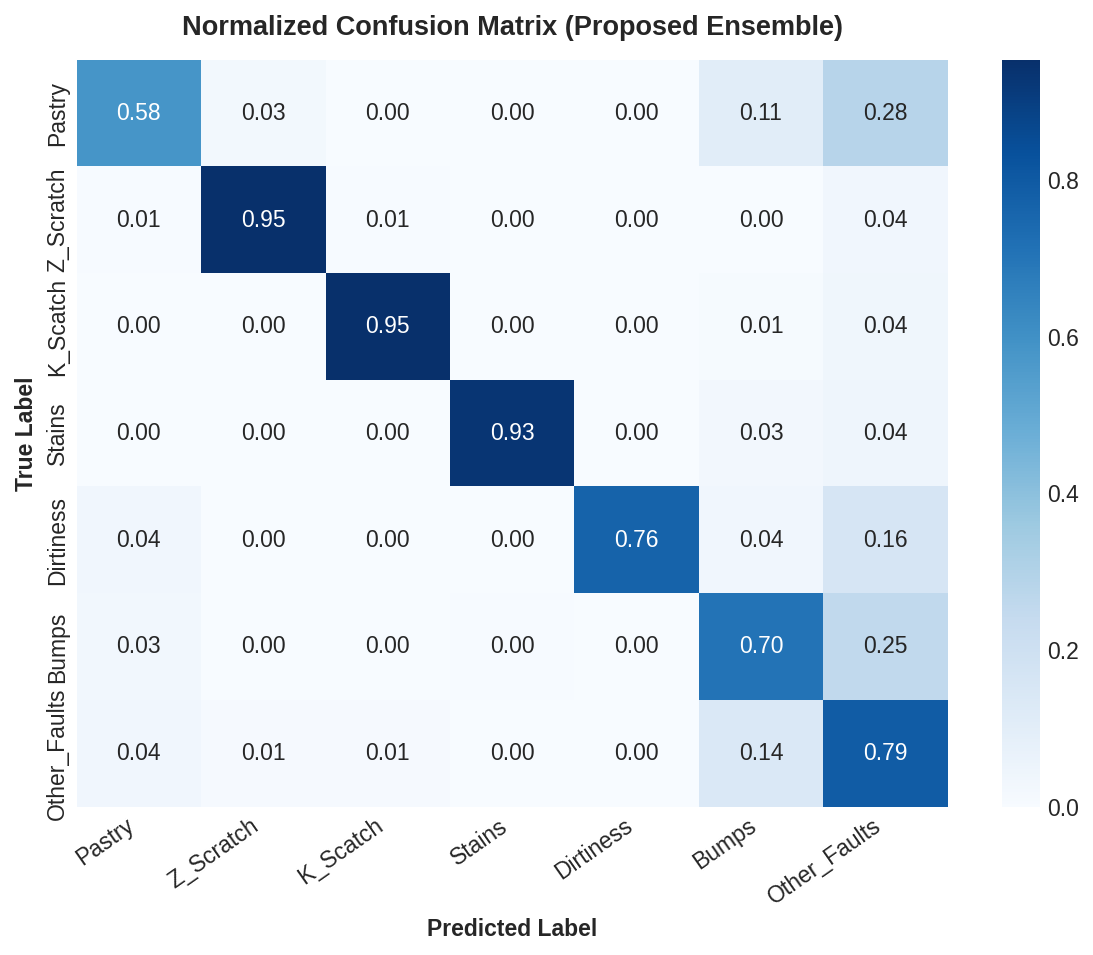

In [40]:
fig, ax = plt.subplots(figsize=(8, 6.5))
oof_proposed = oof_dict["Proposed Soft Ensemble"]
cm = confusion_matrix(y, oof_proposed)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=target_cols, yticklabels=target_cols, ax=ax)
ax.set_title("Normalized Confusion Matrix (Proposed Ensemble)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Predicted Label", fontweight='bold')
ax.set_ylabel("True Label", fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix_proposed.png", dpi=300)
plt.show()


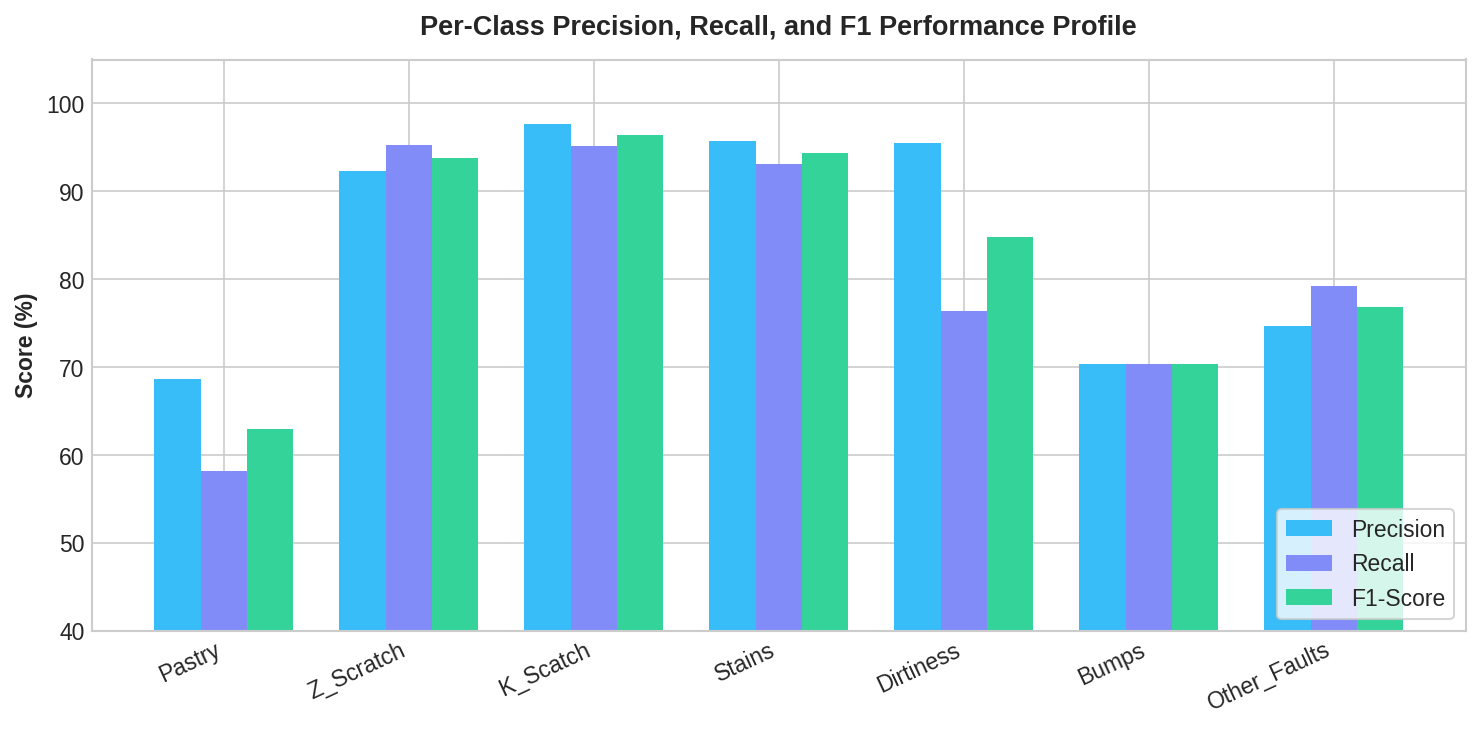


Detailed Per-Class Performance Summary Table:
       Class  Precision    Recall  F1-Score
      Pastry  68.656716 58.227848 63.013699
   Z_Scratch  92.346939 95.263158 93.782383
    K_Scatch  97.637795 95.140665 96.373057
      Stains  95.714286 93.055556 94.366197
   Dirtiness  95.454545 76.363636 84.848485
       Bumps  70.398010 70.398010 70.398010
Other_Faults  74.649860 79.197623 76.856525


In [41]:
rep = classification_report(y, oof_proposed, target_names=target_cols, output_dict=True)
metrics_df = pd.DataFrame({
    "Class": target_cols,
    "Precision": [rep[c]["precision"] * 100 for c in target_cols],
    "Recall": [rep[c]["recall"] * 100 for c in target_cols],
    "F1-Score": [rep[c]["f1-score"] * 100 for c in target_cols]
})

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(target_cols))
w = 0.25

ax.bar(x - w, metrics_df["Precision"], w, label='Precision', color='#38bdf8')
ax.bar(x, metrics_df["Recall"], w, label='Recall', color='#818cf8')
ax.bar(x + w, metrics_df["F1-Score"], w, label='F1-Score', color='#34d399')

ax.set_ylabel("Score (%)", fontweight='bold')
ax.set_title("Per-Class Precision, Recall, and F1 Performance Profile", fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(target_cols, rotation=25, ha='right')
ax.set_ylim(40, 105)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig("per_class_performance_profile.png", dpi=300)
plt.show()

print("\nDetailed Per-Class Performance Summary Table:")
print(metrics_df.to_string(index=False))


In [43]:
# Autonomous execution file complying with instruction 9
with open("Main.py", "w") as f:
    f.write('''"""
Autonomous Execution File (Monsoon 2026 PR Course Submission)
Executes entire pipeline end-to-end and outputs test metrics.
"""
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier

def run_project_pipeline():
    print("Executing Autonomous Pattern Recognition Pipeline...")
    col_path = "Faults27x7_var" if os.path.exists("Faults27x7_var") else "/kaggle/input/datasets/thanhvv/dataset-steel-plates-faults/Faults27x7_var"
    data_path = "Faults.NNA" if os.path.exists("Faults.NNA") else "/kaggle/input/datasets/thanhvv/dataset-steel-plates-faults/Faults.NNA"
    
    with open(col_path, "r", encoding="utf-8") as f:
        col_names = f.read().splitlines()
    df = pd.read_csv(data_path, sep=r"\s+", header=None, names=col_names)
    
    targets = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
    valid = df[targets].sum(axis=1) > 0
    df = df[valid].reset_index(drop=True)
    
    X = df.drop(columns=targets).copy()
    y = df[targets].values.argmax(axis=1)
    
    # Feature extraction
    x_range = (X["X_Maximum"] - X["X_Minimum"]).clip(lower=1.0)
    y_range = (X["Y_Maximum"] - X["Y_Minimum"]).clip(lower=1.0)
    X["Aspect_Ratio"] = y_range / x_range
    total_perim = (X["X_Perimeter"] + X["Y_Perimeter"]).clip(lower=1.0)
    X["Shape_Compactness"] = (total_perim ** 2) / (X["Pixels_Areas"] + 1e-5)
    X["Thickness_Perimeter_Ratio"] = total_perim / X["Steel_Plate_Thickness"].clip(lower=1.0)
    X["Luminosity_Spread"] = X["Maximum_of_Luminosity"] - X["Minimum_of_Luminosity"]
    
    sel = [
        'Length_of_Conveyer', 'TypeOfSteel_A400', 'TypeOfSteel_A300',
        'Steel_Plate_Thickness', 'Log_X_Index', 'Edges_Y_Index', 'LogOfAreas',
        'Sum_of_Luminosity', 'X_Minimum', 'Orientation_Index',
        'Outside_X_Index', 'Pixels_Areas', 'Square_Index', 'X_Maximum',
        'X_Perimeter', 'Minimum_of_Luminosity', 'Empty_Index', 'Y_Maximum',
        'Aspect_Ratio', 'Shape_Compactness', 'Thickness_Perimeter_Ratio', 'Luminosity_Spread'
    ]
    X_sub = X[[c for c in sel if c in X.columns]]
    
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    scores = []
    
    for train_idx, val_idx in skf.split(X_sub, y):
        X_tr, X_va = X_sub.iloc[train_idx], X_sub.iloc[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]
        
        clf = VotingClassifier(
            estimators=[
                ('xgb', XGBClassifier(n_estimators=220, max_depth=5, learning_rate=0.06, eval_metric="mlogloss", random_state=42, verbosity=0)),
                ('lgb', LGBMClassifier(n_estimators=220, max_depth=6, num_leaves=31, learning_rate=0.06, random_state=42, verbose=-1)),
                ('cat', CatBoostClassifier(iterations=250, depth=6, learning_rate=0.06, random_seed=42, verbose=0)),
                ('et', ExtraTreesClassifier(n_estimators=250, max_depth=14, random_state=42, n_jobs=-1))
            ],
            voting='soft', weights=[2.5, 2.5, 2.0, 1.0]
        )
        clf.fit(X_tr, y_tr)
        preds = np.asarray(clf.predict(X_va)).ravel().astype(int)
        scores.append(accuracy_score(y_va, preds) * 100)
        
    print(f"SUCCESS: 10-Fold CV Accuracy = {np.mean(scores):.2f}% ± {np.std(scores):.2f}%")

if __name__ == '__main__':
    run_project_pipeline()
''')
print("Autonomous Main.py script written successfully.")


Autonomous Main.py script written successfully.


In [45]:
!python Main.py 

Executing Autonomous Pattern Recognition Pipeline...
SUCCESS: 10-Fold CV Accuracy = 80.99% ± 1.35%
